In [2]:
import geopandas as gpd
import geowombat as gw
import pandas as pd
from shapely.geometry import Point
import matplotlib.pyplot as plt

C:\Users\hibah\anaconda3\envs\spatial_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df = pd.read_csv("main.csv", sep='\t')
df.head()

,gbifID,datasetKey,occurrenceID,kingdom,phylum,class,order,family,genus,species,...,identifiedBy,dateIdentified,license,rightsHolder,recordedBy,typeStatus,establishmentMeans,lastInterpreted,mediaType,issue
0,3890310317,d85d848d-791e-4055-bda5-32c16619ab21,NCF_India:SeasonWatch:314613,Plantae,Tracheophyta,Magnoliopsida,Lamiales,Bignoniaceae,Jacaranda,Jacaranda mimosifolia,...,NaN,NaN,CC_BY_4_0,NaN,NaN,NaN,NaN,2026-06-12T07:57:46.668Z,NaN,OCCURRENCE_STATUS_INFERRED_FROM_INDIVIDUAL_COUNT
1,3890310412,d85d848d-791e-4055-bda5-32c16619ab21,NCF_India:SeasonWatch:152417,Plantae,Tracheophyta,Magnoliopsida,Rosales,Moraceae,Ficus,Ficus religiosa,...,NaN,NaN,CC_BY_4_0,NaN,NaN,NaN,NaN,2026-06-12T07:57:46.793Z,NaN,OCCURRENCE_STATUS_INFERRED_FROM_INDIVIDUAL_COU...
2,3890310483,d85d848d-791e-4055-bda5-32c16619ab21,NCF_India:SeasonWatch:466076,Plantae,Tracheophyta,Magnoliopsida,Fabales,Fabaceae,Albizia,Albizia lebbeck,...,NaN,NaN,CC_BY_4_0,NaN,NaN,NaN,NaN,2026-06-12T07:57:46.842Z,NaN,OCCURRENCE_STATUS_INFERRED_FROM_INDIVIDUAL_COU...
3,3890310494,d85d848d-791e-4055-bda5-32c16619ab21,NCF_India:SeasonWatch:494988,Plantae,Tracheophyta,Magnoliopsida,Magnoliales,Magnoliaceae,Magnolia,Magnolia champaca,...,NaN,NaN,CC_BY_4_0,NaN,NaN,NaN,NaN,2026-06-12T07:57:46.857Z,NaN,OCCURRENCE_STATUS_INFERRED_FROM_INDIVIDUAL_COUNT
4,3890310529,d85d848d-791e-4055-bda5-32c16619ab21,NCF_India:SeasonWatch:401580,Plantae,Tracheophyta,Magnoliopsida,Fabales,Fabaceae,Peltophorum,Peltophorum pterocarpum,...,NaN,NaN,CC_BY_4_0,NaN,NaN,NaN,NaN,2026-06-12T07:57:46.910Z,NaN,OCCURRENCE_STATUS_INFERRED_FROM_INDIVIDUAL_COUNT


In [4]:
lantana = df[df["species"] == "Lantana camara"]

print(lantana.head())
print(len(lantana))

          gbifID                            datasetKey  \
491   4943263710  d85d848d-791e-4055-bda5-32c16619ab21   
574   4943271625  d85d848d-791e-4055-bda5-32c16619ab21   
833   4943299098  d85d848d-791e-4055-bda5-32c16619ab21   
960   4943313691  d85d848d-791e-4055-bda5-32c16619ab21   
1041  4943322461  d85d848d-791e-4055-bda5-32c16619ab21   

                      occurrenceID  kingdom        phylum          class  \
491   NCF_India:SeasonWatch:496387  Plantae  Tracheophyta  Magnoliopsida   
574   NCF_India:SeasonWatch:344964  Plantae  Tracheophyta  Magnoliopsida   
833   NCF_India:SeasonWatch:243881  Plantae  Tracheophyta  Magnoliopsida   
960   NCF_India:SeasonWatch:577747  Plantae  Tracheophyta  Magnoliopsida   
1041  NCF_India:SeasonWatch:672803  Plantae  Tracheophyta  Magnoliopsida   

         order       family    genus         species  ... identifiedBy  \
491   Lamiales  Verbenaceae  Lantana  Lantana camara  ...          NaN   
574   Lamiales  Verbenaceae  Lantana  Lantana 

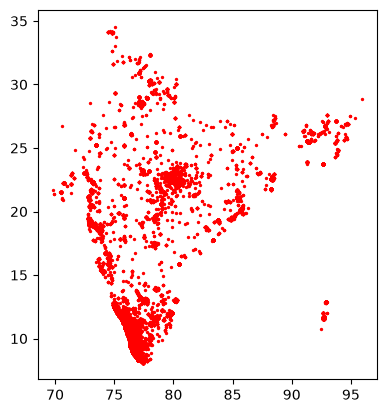

In [5]:
gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["decimalLongitude"], df["decimalLatitude"]),
    crs="EPSG:4326"  # WGS84
)

# Quick map
gdf.plot(markersize=2, color="red")
plt.show()

In [10]:
import glob

files = sorted(glob.glob(r"C:\Users\hibah\rd\image\wc2.1_10m_bio_*.tif"))
print(len(files), "files found")
print(files[:3])


19 files found
['C:\\Users\\hibah\\rd\\image\\wc2.1_10m_bio_1.tif', 'C:\\Users\\hibah\\rd\\image\\wc2.1_10m_bio_10.tif', 'C:\\Users\\hibah\\rd\\image\\wc2.1_10m_bio_11.tif']


In [13]:
gdf = gpd.GeoDataFrame(
    lantana,
    geometry=gpd.points_from_xy(lantana["decimalLongitude"], lantana["decimalLatitude"]),
    crs="EPSG:4326"
)


In [ ]:
gdf.to_csv("lantana_with_bio.csv", index=False)


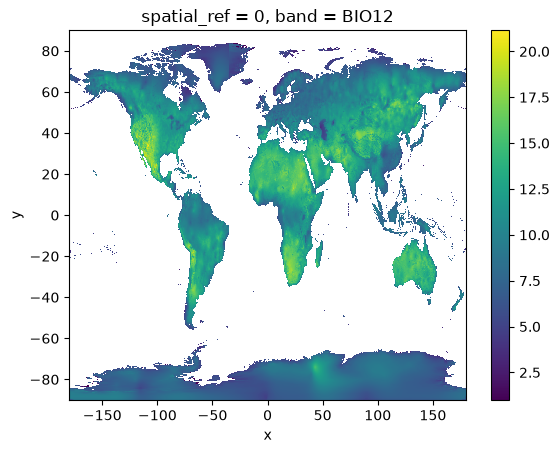

In [15]:
import xarray as xr
import rioxarray

# Stack with xarray and mask NoData values automatically
ds = xr.concat([rioxarray.open_rasterio(f, masked=True) for f in files], dim="band")

# Assign band names
ds = ds.assign_coords(band=[f"BIO{i}" for i in range(1, 20)])

# Plotting will now ignore the ocean/NoData values and show the true color scale for the land!
ds.sel(band="BIO12").plot()